In [1]:
!wget https://www.dropbox.com/s/nilt43hyl1dx82k/dataset.zip?dl=0

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
!unzip dataset.zip?dl=0

'unzip' is not recognized as an internal or external command,
operable program or batch file.


#  Building our Model To train the data 

In [3]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
pip install tensorflow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras

from keras.layers import Flatten, Dense
from keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator , img_to_array, load_img
from keras.applications.mobilenet import MobileNet, preprocess_input 
from keras.losses import categorical_crossentropy

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator , img_to_array, load_img


In [9]:
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator , img_to_array, load_img
from tensorflow.keras.applications.mobilenet import MobileNet, preprocess_input 
from tensorflow.keras.losses import categorical_crossentropy


In [10]:
from keras.models import Model
# from keras.preprocessing.image import ImageDataGenerator , img_to_array, load_img
from tensorflow.keras.preprocessing.image import ImageDataGenerator , img_to_array, load_img
from keras.applications.mobilenet import MobileNet, preprocess_input 
from keras.losses import categorical_crossentropy

In [11]:
# Working with pre trained model 

base_model = MobileNet( input_shape=(224,224,3), include_top= False )

for layer in base_model.layers:
  layer.trainable = False


x = Flatten()(base_model.output)
x = Dense(units=7 , activation='softmax' )(x)

# creating our model.
model = Model(base_model.input, x)

In [12]:
model.compile(optimizer='adam', loss= categorical_crossentropy , metrics=['accuracy']  )

# Preparing our data using data generator

In [13]:
train_datagen = ImageDataGenerator(
     zoom_range = 0.2, 
     shear_range = 0.2, 
     horizontal_flip=True, 
     rescale = 1./255
)

train_data = train_datagen.flow_from_directory(
    directory=r"D:\PROJECTS\Emotion-detection-main\Emotion-detection-main\train\train", 
    target_size=(224,224), 
    batch_size=32
)

train_data.class_indices

Found 350 images belonging to 7 classes.


{'Angry': 0,
 'Disguist': 1,
 'Fear': 2,
 'Happy': 3,
 'Neutral': 4,
 'Sad': 5,
 'Surprise': 6}

In [14]:
val_datagen = ImageDataGenerator(rescale = 1./255 )

val_data = val_datagen.flow_from_directory(
  directory=r"D:\PROJECTS\Emotion-detection-main\Emotion-detection-main\train\train", 
    target_size=(224,224), 
    batch_size=32
                                  )

Found 350 images belonging to 7 classes.


In [15]:
pip install scipy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# visualizaing the data that is fed to train data gen

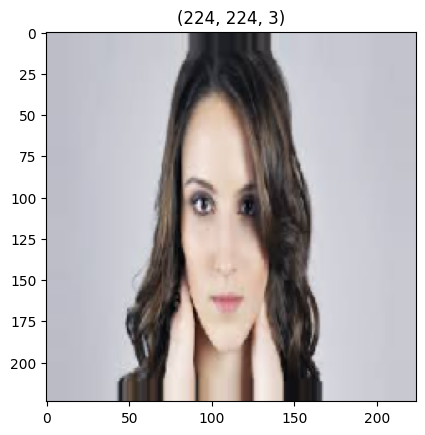

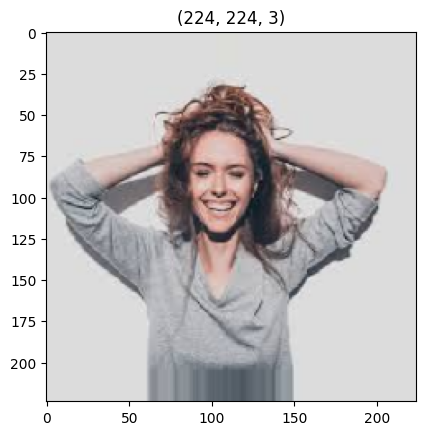

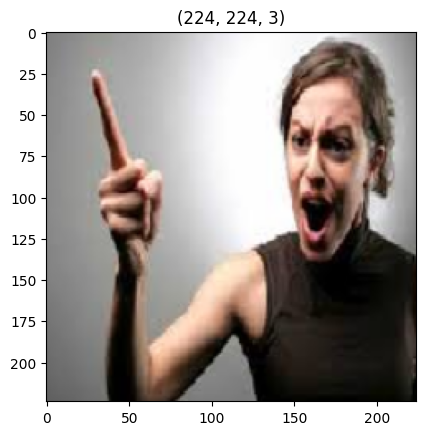

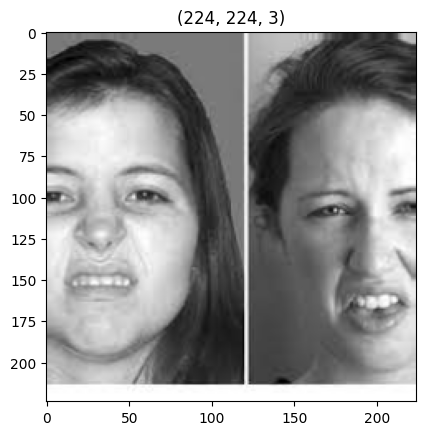

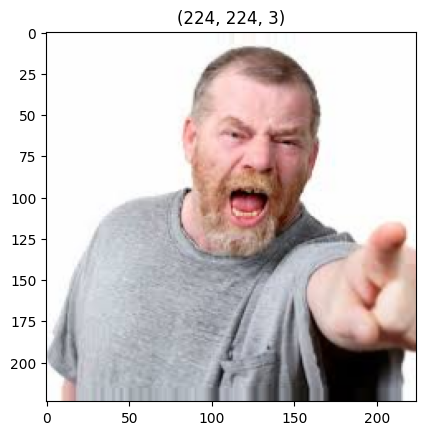

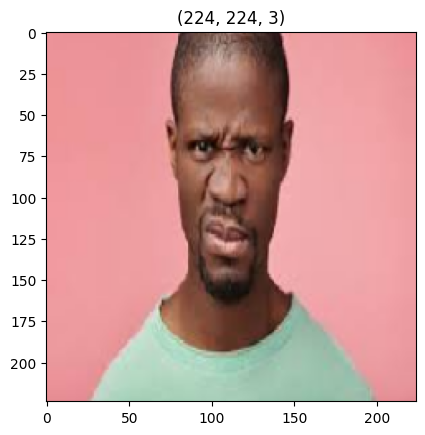

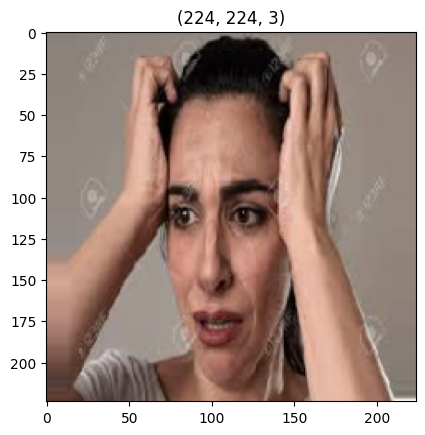

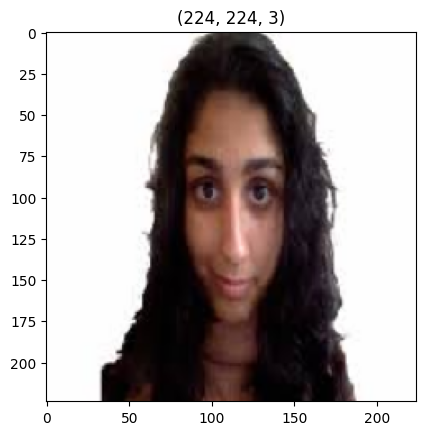

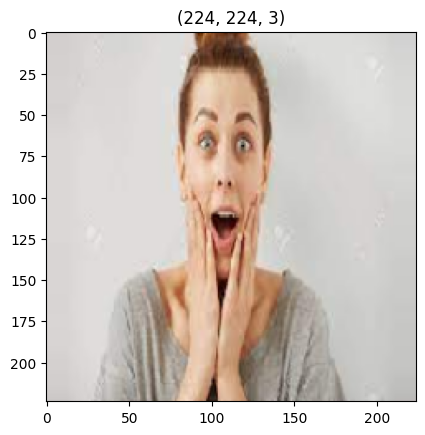

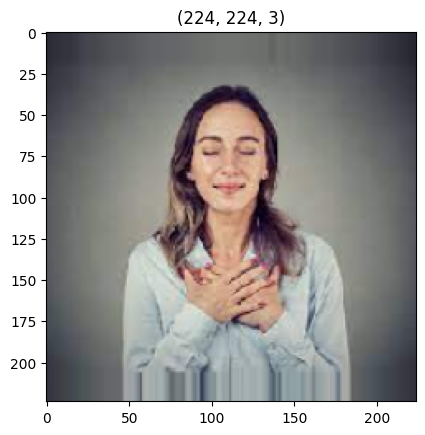

In [16]:
# to visualize the images in the traing data denerator 

t_img , label = next(train_data)
#-----------------------------------------------------------------------------
# function when called will prot the images 
def plotImages(img_arr, label):
  """
  input  :- images array 
  output :- plots the images 
  """
  count = 0
  for im, l in zip(img_arr,label) :
    plt.imshow(im)
    plt.title(im.shape)
    plt.axis = False
    plt.show()
    
    count += 1
    if count == 10:
      break

#-----------------------------------------------------------------------------
# function call to plot the images 
plotImages(t_img, label)

# having early stopping and model check point

In [17]:
## having early stopping and model check point 

from keras.callbacks import ModelCheckpoint, EarlyStopping

# early stopping
es = EarlyStopping(monitor='val_accuracy', min_delta= 0.01 , patience= 5, verbose= 1, mode='auto')

# model check point
mc = ModelCheckpoint(filepath="best_model.h5", monitor= 'val_accuracy', verbose= 1, save_best_only= True, mode = 'auto')

# puting call back in a list 
call_back = [es, mc]

In [18]:
# from keras.callbacks import ModelCheckpoint

# checkpoint = ModelCheckpoint(
#     "best_mod.h5", 
#     monitor='val_loss', 
#     verbose=1, 
#     save_best_only=True, 
#     mode='min'
# )

# model.fit(
#     train_data,
#     validation_data=val_data,
#     epochs=30,
#     callbacks=[checkpoint]
# )


In [ ]:
hist = model.fit(
    train_data, 
    steps_per_epoch=10, 
    epochs=30, 
    validation_data=val_data, 
    validation_steps=30, 
    callbacks=[es, mc]
)


c:\Users\meet\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step - accuracy: 0.1701 - loss: 7.7262
Epoch 1: val_accuracy improved from -inf to 0.20000, saving model to best_model.h5


c:\Users\meet\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.1693 - loss: 8.6830 - val_accuracy: 0.2000 - val_loss: 17.9460
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.2378 - loss: 16.6484
Epoch 2: val_accuracy improved from 0.20000 to 0.31714, saving model to best_model.h5


3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.2435 - loss: 15.9200 - val_accuracy: 0.3171 - val_loss: 9.0890
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.3552 - loss: 11.0208
Epoch 3: val_accuracy improved from 0.31714 to 0.42857, saving model to best_model.h5


...

3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.6654 - loss: 1.8677 - val_accuracy: 0.7771 - val_loss: 1.5014
Epoch 10/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step - accuracy: 0.7795 - loss: 1.5645
Epoch 10: val_accuracy did not improve from 0.77714
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.7747 - loss: 1.5950 - val_accuracy: 0.7771 - val_loss: 1.5491
Epoch 11/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.6858 - loss: 1.9409
Epoch 11: val_accuracy improved from 0.77714 to 0.81143, saving model to best_model.h5


3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.7044 - loss: 1.8050 - val_accuracy: 0.8114 - val_loss: 1.2091
Epoch 12/30
2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.8095 - loss: 1.1526
Epoch 12: val_accuracy did not improve from 0.81143
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.8085 - loss: 1.1851 - val_accuracy: 0.7914 - val_loss: 1.3187
Epoch 13/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.7431 - loss: 1.1318
Epoch 13: val_accuracy improved from 0.81143 to 0.88857, saving model to best_model.h5


3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7474 - loss: 1.1565 - val_accuracy: 0.8886 - val_loss: 0.6074
Epoch 14/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.8247 - loss: 1.1956
Epoch 14: val_accuracy did not improve from 0.88857
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8190 - loss: 1.1849 - val_accuracy: 0.8200 - val_loss: 1.2899
Epoch 15/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.7217 - loss: 1.9213
Epoch 15: val_accuracy improved from 0.88857 to 0.91714, saving model to best_model.h5


3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.7301 - loss: 1.9083 - val_accuracy: 0.9171 - val_loss: 0.5217
Epoch 16/30
2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.8984 - loss: 0.5134
Epoch 16: val_accuracy did not improve from 0.91714
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.8958 - loss: 0.4911 - val_accuracy: 0.8714 - val_loss: 0.7988
Epoch 17/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.8216 - loss: 0.9217
Epoch 17: val_accuracy did not improve from 0.91714
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8183 - loss: 0.9435 - val_accuracy: 0.9086 - val_loss: 0.6188
Epoch 18/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.9115 - loss: 0.3323
Epoch 18: val_accuracy did not improve from 0.91714
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.9102 - loss: 0.3475 - val_accuracy: 0.9143 - val_loss: 0.4117
Epoch 19/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.9653 - loss: 0.1781
Epoch 19: val_accuracy did not improve from 0.91714
3/3 

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8333 - loss: 1.4404 - val_accuracy: 0.9229 - val_loss: 0.3692
Epoch 20: early stopping


In [28]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

# # ✅ Save only the best model (based on lowest validation loss)
# checkpoint = ModelCheckpoint(
#     "best_mod.h5",
#     monitor='val_loss',
#     verbose=1,
#     save_best_only=True,
#     mode='min'
# )

# ✅ Stop training early if val_loss doesn’t improve for 5 epochs
# early_stop = EarlyStopping(
#     monitor='val_loss',
#     patience=5,
#     restore_best_weights=True
# )

# # ✅ Train the model with fewer epochs for faster initial training
# model.fit(
#     train_data,
#     validation_data=val_data,
#     epochs=20,                # Reduce from 30 to 20
#     callbacks=[checkpoint, early_stop],
#     verbose=1
# )


In [21]:
# hist = model.fit(
#     train_data,
#     epochs=30,
#     validation_data=val_data,
#     callbacks=[es, mc]
# )


In [22]:

# # Loading the best fit model 
# from keras.models import load_model
# model = load_model(r"D:\PROJECTS\Emotion-detection-main\Emotion-detection-main\best_model.h5")

from keras.models import load_model

model = load_model("D:\PROJECTS\Emotion-detection-main\Emotion-detection-main/best_model.h5")


In [23]:
h =  hist.history
h.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

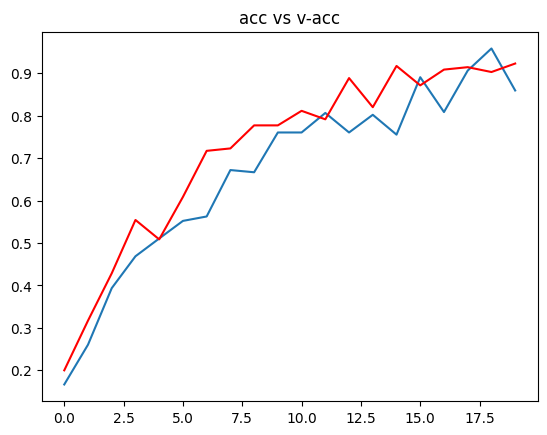

In [24]:
plt.plot(h['accuracy'])
plt.plot(h['val_accuracy'] , c = "red")
plt.title("acc vs v-acc")
plt.show()

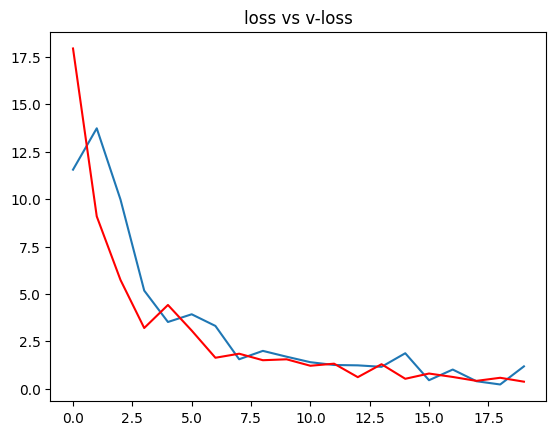

In [25]:
plt.plot(h['loss'])
plt.plot(h['val_loss'] , c = "red")
plt.title("loss vs v-loss")
plt.show()

In [26]:
# just to map o/p values 
op = dict(zip( train_data.class_indices.values(), train_data.class_indices.keys()))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 794ms/step
 the image is of Angry


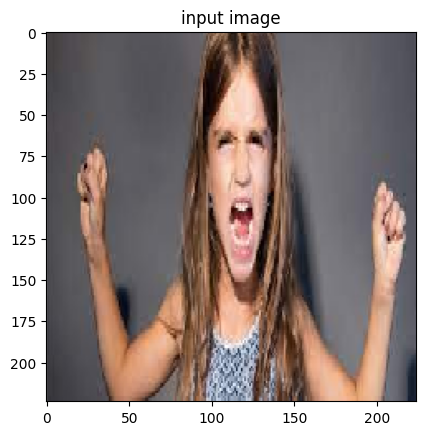

In [27]:
# path for the image to see if it predics correct class

path = r"D:\PROJECTS\Emotion-detection-main\Emotion-detection-main\train\train\Angry\download (1).jpg"
img = load_img(path, target_size=(224,224) )

i = img_to_array(img)/255
input_arr = np.array([i])
input_arr.shape

pred = np.argmax(model.predict(input_arr))

print(f" the image is of {op[pred]}")

# to display the image  
plt.imshow(input_arr[0])
plt.title("input image")
plt.show()